<a href="https://colab.research.google.com/github/Gene7Ai/genai-tps/blob/main/TP4/TP4_PixelCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

For each practical exercise (TP), please work in groups of two or three. Then, create a private GitHub repository and add me (my GitHub is arthur-75) to your project.

# Autoregressive Models (PixelCNN)

## What is an Autoregressive Model in PixelCNN?

Autoregressive models aim to learn the joint distribution of images by factorizing it into conditional distributions. For an image x, composed of pixels xi,j:

$$P(x) = \prod_{i,j} P(x_{i,j} \mid x_{<i,j})$$

where:
x<i,j refers to all pixels above and to the left of pixel xi,j.
PixelCNN strictly enforces this autoregressive dependency using masked convolutions.

## The PixelCNN Architecture Explained

PixelCNN generates images pixel-by-pixel, modeling the conditional probability distribution of each pixel based on previously generated pixels.
Masked Convolution Layers
 These ensure no pixel sees "future" pixels (pixels below or to the right), preserving the autoregressive property.
Residual Blocks
 Improve training stability and performance through skip connections.

## Behind Masked Convolution

### Masked convolution filters enforce conditional dependence:

Type A mask: Used in the first convolutional layer (no current pixel allowed).
Type B mask: Used in subsequent layers (allows current pixel).
Given a convolutional kernel K, mask M, input image X:

$$X_{\text{out}} = X * (K \odot M)$$

Where:
⊙ represents element-wise multiplication.
Mask M ensures the convolution at pixel (i,j) does not include pixels at positions after (i,j).

## Implementation

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
# Parameters
IMAGE_SIZE = 16
PIXEL_LEVELS = 4
N_FILTERS = 128
RESIDUAL_BLOCKS = 5
BATCH_SIZE = 128
EPOCHS = 1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Data Preparation
Load FashionMNIST dataset.
Resize images to smaller dimensions (e.g., 16×16).
Quantize pixel values into fewer discrete levels (e.g., 4 levels) to simplify the probability distribution.

In [7]:
# Data Preparation
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x * 255).float() // (256 // PIXEL_LEVELS))
])
path= "./data"
dataset = datasets.FashionMNIST(root=path, train=True, download=True, transform=transform)
data_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

Masked Convolution Layer
Implement convolutional layers with masks:
Type A: For the initial layer, exclude the pixel itself.
Type B: For all subsequent layers, allow the current pixel.

In [3]:
# Masked Convolution Layer
class MaskedConv2d(nn.Conv2d):
    def __init__(self, mask_type, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.register_buffer('mask', self.weight.data.clone())
        _, _, h, w = self.weight.size()
        self.mask.fill_(1)
        self.mask[:, :, h // 2, w // 2 + (mask_type == 'B'):] = 0
        self.mask[:, :, h // 2 + 1:] = 0

    def forward(self, x):
        self.weight.data *= self.mask
        return super().forward(x)

Residual Blocks
Combine masked convolutions and non-linear activations with skip-connections:

In [4]:
# Residual Block
class ResidualBlock(nn.Module):
    def __init__(self, filters):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(filters, filters // 2, kernel_size=1),
            nn.ReLU(),
            MaskedConv2d('B', filters // 2, filters // 2, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(filters // 2, filters, kernel_size=1)
        )

    def forward(self, x):
        return x + self.block(x)

PixelCNN Model Structure
Stack masked convolution layers and residual blocks.
Output layer predicts probability distribution over pixel intensities using softmax activation.

In [8]:
# PixelCNN Model
class PixelCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            MaskedConv2d('A', 1, N_FILTERS, kernel_size=7, padding=3),
            *[ResidualBlock(N_FILTERS) for _ in range(RESIDUAL_BLOCKS)],
            nn.ReLU(),
            MaskedConv2d('B', N_FILTERS, N_FILTERS, kernel_size=1),
            nn.ReLU(),
            MaskedConv2d('B', N_FILTERS, N_FILTERS, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(N_FILTERS, PIXEL_LEVELS, kernel_size=1)
        )

    def forward(self, x):
        return self.model(x)

model = PixelCNN().to(DEVICE)

## 📉 5. Training the PixelCNN

### Objective:

Minimize the cross-entropy loss between predicted pixel distributions and actual pixel intensities.
Cross-Entropy Loss:

$$\mathcal{L}(x, y) = -\sum_c y_c \log(\hat{x}_c)$$

yc is the true class label (pixel intensity category).
xc is the predicted probability for class c.

### Training Loop (Conceptual):

Forward pass:
Input: images (floats).
Output: predicted probabilities for each pixel intensity.
Compute cross-entropy loss.
Backward pass and optimizer update (e.g., Adam optimizer).

In [9]:
optimizer = optim.Adam(model.parameters(), lr=0.0005)
criterion = nn.CrossEntropyLoss()
# Training Loop
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for images, _ in tqdm(data_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):

        images = images.to(DEVICE).squeeze(1)
        optimizer.zero_grad()
        inputs = images.float().unsqueeze(1)     # [batch, 1, H, W]
        targets = images.long()                  # [batch, H, W]
        outputs = model(inputs)                  # [batch, PIXEL_LEVELS, H, W]
        loss = criterion(outputs, targets)       # CrossEntropy expects float inputs and long targets
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(data_loader)
    print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

Epoch 1/1: 100%|██████████| 469/469 [15:33<00:00,  1.99s/it]

Epoch 1, Loss: 0.4302


### Load the pretrained model

The teacher's model is in the drive (`cours 3 AR/models/PixelCNN.pt`).

In [10]:
import os
import gdown

os.makedirs("models", exist_ok=True)
if not os.path.exists("models/PixelCNN.pt"):
    gdown.download(id="1jEQP8wNjJSvZyUT1AyhZDousykg-Y3wf", output="models/PixelCNN.pt")
model.load_state_dict(torch.load("models/PixelCNN.pt", map_location=DEVICE))
model.eval()

Downloading...
From: https://drive.google.com/uc?id=1jEQP8wNjJSvZyUT1AyhZDousykg-Y3wf
To: /content/models/PixelCNN.pt
100%|██████████| 2.14M/2.14M [00:00<00:00, 133MB/s]


PixelCNN(
  (model): Sequential(
    (0): MaskedConv2d(1, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): ResidualBlock(
      (block): Sequential(
        (0): ReLU()
        (1): Conv2d(128, 64, kernel_size=(1, 1), stride=(1, 1))
        (2): ReLU()
        (3): MaskedConv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): ReLU()
        (5): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1))
      )
    )
    (2): ResidualBlock(
      (block): Sequential(
        (0): ReLU()
        (1): Conv2d(128, 64, kernel_size=(1, 1), stride=(1, 1))
        (2): ReLU()
        (3): MaskedConv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): ReLU()
        (5): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1))
      )
    )
    (3): ResidualBlock(
      (block): Sequential(
        (0): ReLU()
        (1): Conv2d(128, 64, kernel_size=(1, 1), stride=(1, 1))
        (2): ReLU()
        (3): MaskedConv2d(64, 64, kernel_size=(3, 3), s

## Sampling (Generating Images with PixelCNN)

PixelCNN samples pixels sequentially from the learned distribution:

### Sampling Steps:

Initialize: Create an empty (zero-valued) image tensor.
Sequential Sampling: Iterate through each pixel position (i,j):
Compute conditional probability:

$$P(x_{i,j} \mid x_{<i,j}) = \mathrm{softmax}\left(\frac{\mathrm{logits}(x_{<i,j})}{T}\right)$$

Sample pixel intensity from the probability distribution:

$$x_{i,j} \sim P(x_{i,j} \mid x_{<i,j})$$

Update pixel value in the generated image.

### Role of Temperature T:

Controls randomness:
Lower T → less randomness, sharper images.
Higher T → more randomness, diverse images.

### Formally:

For each pixel, given logits z:

$$P(x_{i,j} = c \mid x_{<i,j}) = \frac{\exp(z_c / T)}{\sum_k \exp(z_k / T)}$$

Then we sample from this distribution:

$$x_{i,j} \sim \mathrm{Categorical}\big(P(x_{i,j} \mid x_{<i,j})\big)$$

In [11]:
def generate_images(model, num_images, temperature=1.0):
    model.eval()
    generated = torch.zeros(num_images, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    with torch.no_grad():
        for row in range(IMAGE_SIZE):
            for col in range(IMAGE_SIZE):
                logits = model(generated.float())[:, :, row, col] / temperature
                probs = torch.softmax(logits, dim=-1)
                generated[:, 0, row, col] = torch.multinomial(probs, 1).squeeze(-1)
    return generated.cpu().numpy() / PIXEL_LEVELS

# Generate sample images
sample_images = generate_images(model, num_images=10)
print("Generated images shape:", sample_images.shape)

Generated images shape: (10, 1, 16, 16)


## Visualizing Generated Images

Generated images have pixel values between 0 and 1.
Display images using visualization libraries (e.g., matplotlib) to inspect model quality.

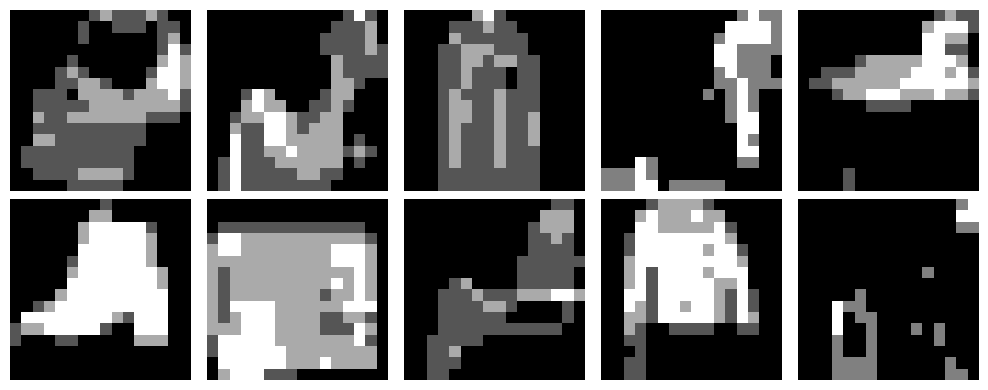

In [12]:
def plot_generated_images(images, n_cols=5):
    n_rows = (len(images) + n_cols - 1) // n_cols
    plt.figure(figsize=(2 * n_cols, 2 * n_rows))

    for idx, img in enumerate(images):
        plt.subplot(n_rows, n_cols, idx + 1)
        plt.imshow(img.squeeze(), cmap='gray')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Generate sample images (assuming you've done this step already)
sample_images = generate_images(model, num_images=10, temperature=1.0)
# Plot generated images
plot_generated_images(sample_images)